# Copper DoE Notebook

This notebook prepares the first copper screening matrix. The factor levels are stored in `copper_doe_levels.json`, so the low, center, and high values can be changed there without editing the design code.

## FFD Matrices

### Copper Definitive Screening Design

This is a 13-run Definitive Screening Design for five continuous factors. The coded matrix uses `-1` for low, `0` for center, and `+1` for high. Line width is fixed at 0.62 mm and wall order is fixed at inner/outer.

In [ ]:
from pathlib import Path
import importlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import copper_doe_analysis
importlib.reload(copper_doe_analysis)

from copper_doe_analysis import (
    build_copper_anova_table,
    build_copper_desirability_table,
    build_copper_paired_measurement_table,
    build_copper_term_significance_table,
    default_dsd_terms,
    fit_copper_response_model,
    plot_copper_actual_vs_predicted,
    plot_copper_anova,
    plot_copper_contours,
    plot_copper_curvature,
    plot_copper_desirability,
    plot_copper_interactions,
    plot_copper_main_effects,
    plot_copper_measurement_correlation,
    plot_copper_normal_effects,
    plot_copper_pareto,
    plot_copper_residuals,
    plot_copper_weight_measurements,
)


CONFIG_PATH = Path("copper_doe_levels.json")
if not CONFIG_PATH.exists():
    CONFIG_PATH = Path("3D_Printing_Project") / CONFIG_PATH

with CONFIG_PATH.open("r", encoding="utf-8") as config_file:
    copper_config = json.load(config_file)

copper_factors = copper_config["factors"]
copper_factor_names = [factor["name"] for factor in copper_factors]
copper_factor_levels = {
    factor["name"]: {-1: factor["low"], 0: factor["center"], 1: factor["high"]}
    for factor in copper_factors
}

copper_fixed_settings = copper_config["fixed_settings"]
copper_run_labels = [f"T{i}" for i in range(1, 14)]

The table below is read directly from the JSON file. Change the JSON values if the screening range needs to be adjusted.

In [2]:
copper_level_table = pd.DataFrame(
    [
        {
            "Factor": factor["display_name"],
            "Column": factor["name"],
            "Low (-1)": factor["low"],
            "Center (0)": factor["center"],
            "High (+1)": factor["high"],
            "Unit": factor["unit"],
        }
        for factor in copper_factors
    ]
)

display(copper_level_table)
display(pd.DataFrame([copper_fixed_settings]))

,Factor,Column,Low (-1),Center (0),High (+1),Unit
0,Layer height,A_layer_height_mm,0.18,0.2,0.22,mm
1,Flow ratio,B_flow_ratio,1.18,1.2,1.22,
2,Nozzle temperature,C_nozzle_temp_C,215.00,220.0,225.00,deg C
3,Speed,D_speed_mm_s,60.00,70.0,80.00,mm/s
4,Infill,E_infill_percent,90.00,92.5,95.00,%


,line_width_mm,wall_order
0,0.62,inner/outer


The coded matrix is the actual Definitive Screening Design. The 13 runs come from the five-factor DSD structure: paired high/low rows plus one center row. This keeps the main effects balanced while still allowing curvature screening.

In [3]:
copper_dsd_coded_values = [
    [ 1,  1,  1,  1,  1],
    [ 0,  1, -1, -1,  1],
    [ 1,  0,  1, -1, -1],
    [-1,  1,  0,  1, -1],
    [-1, -1,  1,  0,  1],
    [ 1, -1, -1,  1,  0],
    [-1, -1, -1, -1, -1],
    [ 0, -1,  1,  1, -1],
    [-1,  0, -1,  1,  1],
    [ 1, -1,  0, -1,  1],
    [ 1,  1, -1,  0, -1],
    [-1,  1,  1, -1,  0],
    [ 0,  0,  0,  0,  0],
]

copper_dsd_coded = pd.DataFrame(
    copper_dsd_coded_values,
    columns=copper_factor_names,
)
copper_dsd_coded.insert(0, "Run", copper_run_labels)

display(copper_dsd_coded)

,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent
0,T1,1,1,1,1,1
1,T2,0,1,-1,-1,1
2,T3,1,0,1,-1,-1
3,T4,-1,1,0,1,-1
4,T5,-1,-1,1,0,1
5,T6,1,-1,-1,1,0
6,T7,-1,-1,-1,-1,-1
7,T8,0,-1,1,1,-1
8,T9,-1,0,-1,1,1
9,T10,1,-1,0,-1,1


The real matrix below converts each coded level to the printer setting from the JSON file. The fixed settings are added to every run because they are intentionally not part of the screening design.

In [4]:
def coded_to_real_value(factor_name, coded_value):
    return copper_factor_levels[factor_name][int(coded_value)]


copper_dsd_real = copper_dsd_coded.copy()
for factor_name in copper_factor_names:
    copper_dsd_real[factor_name] = copper_dsd_real[factor_name].map(
        lambda coded_value: coded_to_real_value(factor_name, coded_value)
    )

for setting_name, setting_value in copper_fixed_settings.items():
    copper_dsd_real[setting_name] = setting_value

display(copper_dsd_real)

,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,line_width_mm,wall_order
0,T1,0.22,1.22,225,80,95.0,0.62,inner/outer
1,T2,0.20,1.22,215,60,95.0,0.62,inner/outer
2,T3,0.22,1.20,225,60,90.0,0.62,inner/outer
3,T4,0.18,1.22,220,80,90.0,0.62,inner/outer
4,T5,0.18,1.18,225,70,95.0,0.62,inner/outer
5,T6,0.22,1.18,215,80,92.5,0.62,inner/outer
6,T7,0.18,1.18,215,60,90.0,0.62,inner/outer
7,T8,0.20,1.18,225,80,90.0,0.62,inner/outer
8,T9,0.18,1.20,215,80,95.0,0.62,inner/outer
9,T10,0.22,1.18,220,60,95.0,0.62,inner/outer


## Measurement Table

The measured weights and print notes are stored in `copper_doe_measurements.json`. Edit that JSON file when new copper runs are measured.

In [5]:
MEASUREMENT_PATH = Path("copper_doe_measurements.json")
if not MEASUREMENT_PATH.exists():
    MEASUREMENT_PATH = Path("3D_Printing_Project") / MEASUREMENT_PATH

with MEASUREMENT_PATH.open("r", encoding="utf-8") as measurement_file:
    copper_measurement_config = json.load(measurement_file)

COPPER_FILAMENT_DENSITY_G_CM3 = copper_measurement_config["filament_density_g_cm3"]
if COPPER_FILAMENT_DENSITY_G_CM3 <= 0:
    raise ValueError("Copper filament density must be greater than zero.")

copper_measurements = pd.DataFrame(copper_measurement_config["runs"])
copper_measurements = copper_measurements.rename(columns={"run": "Run"})

copper_density = pd.to_numeric(copper_measurements["density_g_cm3"], errors="coerce")
copper_measurements["relative_density_percent"] = (
    copper_density / COPPER_FILAMENT_DENSITY_G_CM3 * 100
)
copper_measurements["porosity_percent"] = (
    100 - copper_measurements["relative_density_percent"]
)

factor_cols = [factor["name"] for factor in copper_config["factors"]]
response_cols = [
    "weight_measurements_g",
    "weight_g",
    "weight_in_air_g",
    "weight_in_water_g",
    "volume_cm3",
    "notes",
    "density_g_cm3",
    "relative_density_percent",
    "porosity_percent",
    "leakage_rate",
    "log_leakage_rate",
    "visible_clumping_score",
]

planned_measurements = copper_measurements[
    copper_measurements["Run"].isin(copper_dsd_real["Run"])
]
copper_measurement_table = copper_dsd_real.merge(
    planned_measurements[["Run", *response_cols]],
    on="Run",
    how="left",
)

extra_measurements = copper_measurements[
    ~copper_measurements["Run"].isin(copper_dsd_real["Run"])
].copy()
if not extra_measurements.empty:
    extra_columns = ["Run", *factor_cols, *response_cols]
    for column in extra_columns:
        if column not in extra_measurements:
            extra_measurements[column] = pd.NA
    copper_measurement_table = pd.concat(
        [copper_measurement_table, extra_measurements[extra_columns]],
        ignore_index=True,
    )

MEASUREMENT_OFFSET_EXCLUDED_RUNS = ["T16", "T17"]
offset_calibration_pairs = build_copper_paired_measurement_table(
    copper_measurement_table,
    exclude_runs=MEASUREMENT_OFFSET_EXCLUDED_RUNS,
)
MEASUREMENT_1_OFFSET_G = offset_calibration_pairs[
    "offset_2_minus_1_g"
].mean()

display(copper_measurement_table)


,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,line_width_mm,wall_order,weight_g,notes,density_g_cm3,porosity_percent,leakage_rate,log_leakage_rate,visible_clumping_score
0,T1,0.22,1.22,225.0,80.0,95.0,0.62,inner/outer,47.429,many blobs.,None,None,None,None,None
1,T2,0.20,1.22,215.0,60.0,95.0,0.62,inner/outer,47.305,still many blobs which fall off. Prime tower s...,None,None,None,None,None
2,T3,0.22,1.20,225.0,60.0,90.0,0.62,inner/outer,44.554,"less material adhering to nozzle, line missing...",None,None,None,None,None
3,T4,0.18,1.22,220.0,80.0,90.0,0.62,inner/outer,44.932,"again more clumping, but not excessive",None,None,None,None,None
4,T5,0.18,1.18,225.0,70.0,95.0,0.62,inner/outer,45.106,,None,None,None,None,None
5,T6,0.22,1.18,215.0,80.0,92.5,0.62,inner/outer,44.484,less stuff on nozzle.,None,None,None,None,None
6,T7,0.18,1.18,215.0,60.0,90.0,0.62,inner/outer,43.286,looks surprisingly good but holes between infi...,None,None,None,None,None
7,T8,0.20,1.18,225.0,80.0,90.0,0.62,inner/outer,43.294,wieder mehr an der nozzle. Viel zwischenwand u...,None,None,None,None,None
8,T9,0.18,1.20,215.0,80.0,95.0,0.62,inner/outer,46.487,,None,None,None,None,None
9,T10,0.22,1.18,220.0,60.0,95.0,0.62,inner/outer,45.299,,None,None,None,None,None


### Copper Weight Measurements and Repeats

Blue bars show every raw weighing of each original print. The hatched orange segment shows the constant offset added to measurement 1, green bars show separately printed repeat specimens, and the black dot-line shows the offset-corrected mean. T16 and T17 are not offset-corrected.

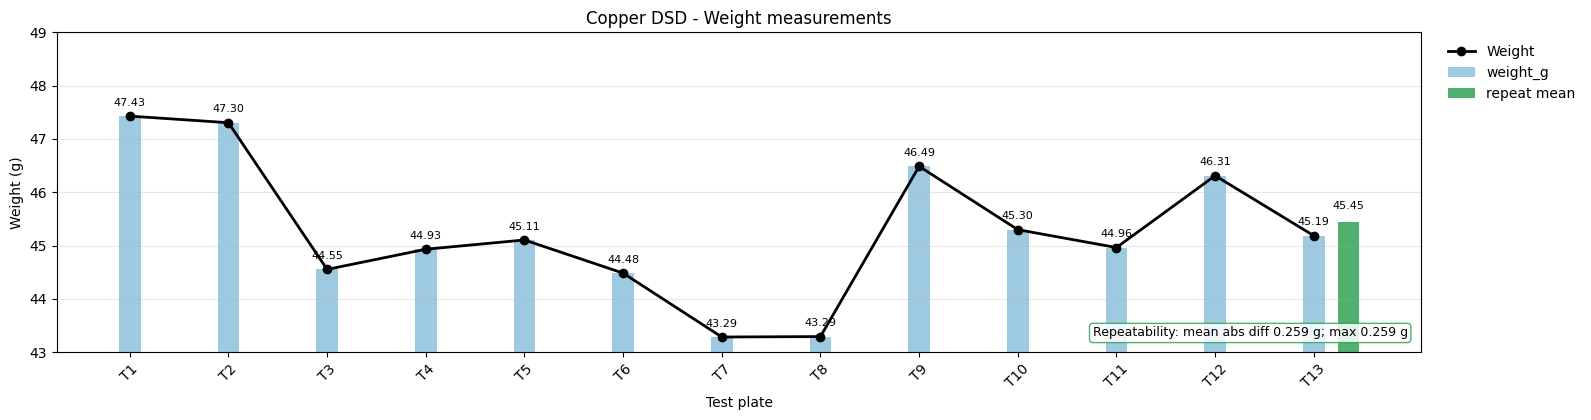

In [6]:
plot_copper_weight_measurements(
    copper_measurement_table,
    response="weight_g",
    measurement_1_offset_g=MEASUREMENT_1_OFFSET_G,
    offset_excluded_runs=MEASUREMENT_OFFSET_EXCLUDED_RUNS,
    base_runs=[f"T{i}" for i in range(1, 14)],
    repeat_runs=["T1.1", "T3.2", "T7.2", "T8.2", "T13.1", "T13.2"],
    extra_runs=[],
    y_min=43,
    y_max=52,
    value_digits=2,
    reference_weight_g=47,
    reference_label="m_geom",
    show_weight_line=True,
)


### Augmented Copper Weight Measurements: T1-T17

This plot keeps `T1`-`T13` as the original DSD sequence and adds `T14`-`T17` in orange on the right.

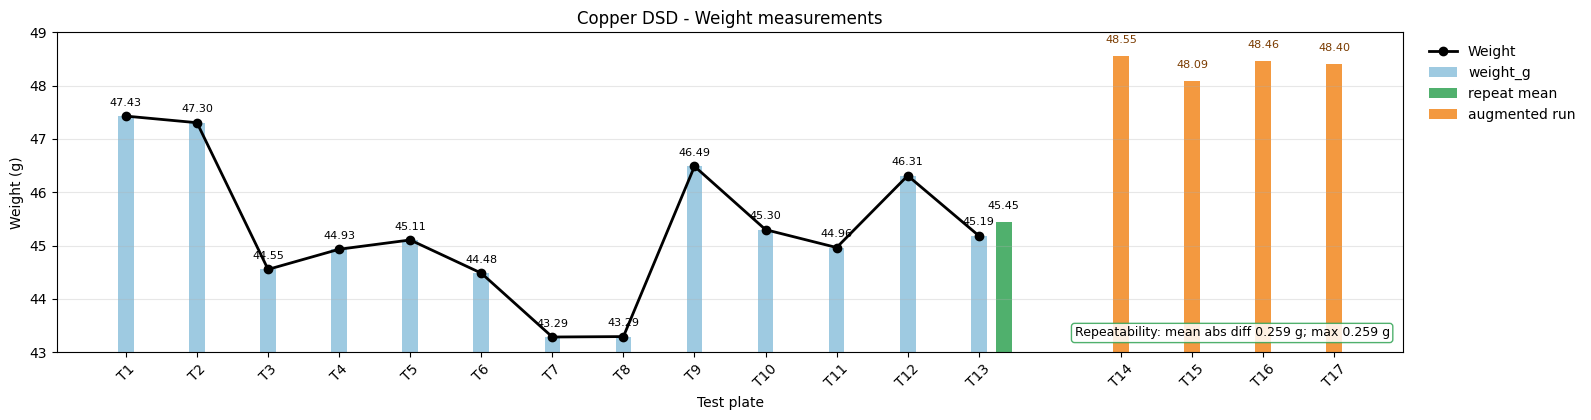

In [7]:
plot_copper_weight_measurements(
    copper_measurement_table,
    response="weight_g",
    measurement_1_offset_g=MEASUREMENT_1_OFFSET_G,
    offset_excluded_runs=MEASUREMENT_OFFSET_EXCLUDED_RUNS,
    base_runs=[f"T{i}" for i in range(1, 14)],
    repeat_runs=["T1.1", "T3.2", "T7.2", "T8.2", "T13.1", "T13.2", "T17.1"],
    extra_runs=[f"T{i}" for i in range(14, 18)],
    y_min=43,
    y_max=52,
    value_digits=2,
    reference_weight_g=47,
    reference_label="m_geom",
    show_weight_line=True,
)


### Offset and Correlation Between Repeated Measurements

The offset is defined as **measurement 2 minus measurement 1**. The correlation panel measures association, while the offset panel checks whether the difference is consistent across specimens.

In [ ]:
copper_paired_measurements = offset_calibration_pairs.copy()

offsets = copper_paired_measurements["offset_2_minus_1_g"]
measurement_correlation = copper_paired_measurements[
    ["measurement_1_g", "measurement_2_g"]
].corr().iloc[0, 1]
offset_summary = pd.Series({
    "paired specimens": len(copper_paired_measurements),
    "mean offset (g)": offsets.mean(),
    "median offset (g)": offsets.median(),
    "offset standard deviation (g)": offsets.std(ddof=1),
    "minimum offset (g)": offsets.min(),
    "maximum offset (g)": offsets.max(),
    "Pearson correlation r": measurement_correlation,
}, name="value")

display(copper_paired_measurements.round(3))
display(offset_summary.to_frame().round(3))
plot_copper_measurement_correlation(
    copper_measurement_table,
    exclude_runs=MEASUREMENT_OFFSET_EXCLUDED_RUNS,
)


## Original Copper DSD Analysis: T1-T13

These plots use only the original 13-run Definitive Screening Design. `T14`-`T17` are intentionally excluded here so this remains the clean DSD model.

In [8]:
COPPER_RESPONSE = "weight_g"

COPPER_SELECTED_INTERACTIONS = [
    ("B_flow_ratio", "E_infill_percent"),
    ("B_flow_ratio", "A_layer_height_mm"),
    ("C_nozzle_temp_C", "D_speed_mm_s"),
    ("B_flow_ratio", "D_speed_mm_s"),
    ("A_layer_height_mm", "C_nozzle_temp_C"),
]

COPPER_CONTOUR_PAIRS = [
    ("B_flow_ratio", "A_layer_height_mm"),
    ("B_flow_ratio", "E_infill_percent"),
    ("B_flow_ratio", "D_speed_mm_s"),
    ("A_layer_height_mm", "C_nozzle_temp_C"),
    ("A_layer_height_mm", "E_infill_percent"),
    ("A_layer_height_mm", "D_speed_mm_s"),
    ("B_flow_ratio", "C_nozzle_temp_C"),
    ("C_nozzle_temp_C", "D_speed_mm_s"),
    ("D_speed_mm_s", "E_infill_percent"),
]

planned_coded_response_table = copper_dsd_coded.merge(
    copper_measurements[["Run", *response_cols]],
    on="Run",
    how="left",
)

def code_extra_copper_runs(extra_measurements):
    extra_coded_rows = []
    for _, row in extra_measurements.iterrows():
        coded_row = {"Run": row["Run"]}
        has_all_factor_settings = True
        for factor in copper_factor_names:
            real_value = row.get(factor)
            if pd.isna(real_value):
                has_all_factor_settings = False
                break
            real_to_coded = {
                real_level: coded_level
                for coded_level, real_level in copper_factor_levels[factor].items()
            }
            if real_value not in real_to_coded:
                raise ValueError(f"{row['Run']} has {factor}={real_value}, which is not one of the configured levels.")
            coded_row[factor] = real_to_coded[real_value]
        if has_all_factor_settings:
            for column in copper_measurements.columns:
                if column != "Run" and column not in coded_row:
                    coded_row[column] = row[column]
            extra_coded_rows.append(coded_row)
    return pd.DataFrame(extra_coded_rows)

extra_copper_measurements = copper_measurements[
    ~copper_measurements["Run"].isin(copper_dsd_coded["Run"])
].copy()
extra_coded_response_table = code_extra_copper_runs(extra_copper_measurements)

# Original DSD model: keep the 13 planned screening runs separate.
copper_coded_response_table = planned_coded_response_table.copy()
original_measured_count = copper_coded_response_table[COPPER_RESPONSE].notna().sum()

# Augmented model: add T14-T17 and both additional T13 center repeats.
augmented_run_labels = [
    *[f"T{i}" for i in range(1, 18)],
    "T13.1",
    "T13.2",
]
augmented_extra_table = extra_coded_response_table[
    extra_coded_response_table["Run"].isin(augmented_run_labels)
].copy()
copper_augmented_response_table = pd.concat(
    [copper_coded_response_table, augmented_extra_table],
    ignore_index=True,
)
run_parts = copper_augmented_response_table["Run"].str.extract(
    r"T(\d+)(?:\.(\d+))?"
)
copper_augmented_response_table["run_order"] = run_parts[0].astype(float)
copper_augmented_response_table["repeat_order"] = run_parts[1].fillna(0).astype(float)
copper_augmented_response_table = (
    copper_augmented_response_table
    .sort_values(["run_order", "repeat_order"])
    .drop(columns=["run_order", "repeat_order"])
    .reset_index(drop=True)
)
augmented_measured_count = copper_augmented_response_table[COPPER_RESPONSE].notna().sum()

main_effect_terms = default_dsd_terms(copper_factor_names)
quadratic_terms = default_dsd_terms(copper_factor_names, include_quadratic=True)

if original_measured_count >= len(quadratic_terms) + 1:
    copper_model_terms = quadratic_terms
else:
    copper_model_terms = main_effect_terms

if augmented_measured_count >= len(quadratic_terms) + 1:
    copper_augmented_model_terms = quadratic_terms
else:
    copper_augmented_model_terms = main_effect_terms

measured_count = original_measured_count

print(f"Response: {COPPER_RESPONSE}")
print(f"Original DSD measured runs: {original_measured_count}/{len(copper_coded_response_table)}")
print("Original DSD model terms:", copper_model_terms)
print(f"Augmented measured runs: {augmented_measured_count}/{len(copper_augmented_response_table)}")
print("Augmented model terms:", copper_augmented_model_terms)
print(
    "T1-T13 stays as the original DSD model. T13.1, T13.2, and T14-T17 are included in the augmented regression model."
)

print("Original DSD table: T1-T13")
display(copper_coded_response_table[["Run", *copper_factor_names, COPPER_RESPONSE, "notes"]])
print("Augmented table: T1-T17 plus T13.1 and T13.2")
display(copper_augmented_response_table[["Run", *copper_factor_names, COPPER_RESPONSE, "notes"]])


Response: weight_g
Original DSD measured runs: 13/13
Original DSD model terms: ['A_layer_height_mm', 'B_flow_ratio', 'C_nozzle_temp_C', 'D_speed_mm_s', 'E_infill_percent', 'A_layer_height_mm^2', 'B_flow_ratio^2', 'C_nozzle_temp_C^2', 'D_speed_mm_s^2', 'E_infill_percent^2']
Augmented measured runs: 17/17
Augmented model terms: ['A_layer_height_mm', 'B_flow_ratio', 'C_nozzle_temp_C', 'D_speed_mm_s', 'E_infill_percent', 'A_layer_height_mm^2', 'B_flow_ratio^2', 'C_nozzle_temp_C^2', 'D_speed_mm_s^2', 'E_infill_percent^2']
T1-T13 stays as the original DSD model. T14-T17 are added only in the augmented regression model.
Original DSD table: T1-T13


,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,weight_g,notes
0,T1,1,1,1,1,1,47.429,many blobs.
1,T2,0,1,-1,-1,1,47.305,still many blobs which fall off. Prime tower s...
2,T3,1,0,1,-1,-1,44.554,"less material adhering to nozzle, line missing..."
3,T4,-1,1,0,1,-1,44.932,"again more clumping, but not excessive"
4,T5,-1,-1,1,0,1,45.106,
5,T6,1,-1,-1,1,0,44.484,less stuff on nozzle.
6,T7,-1,-1,-1,-1,-1,43.286,looks surprisingly good but holes between infi...
7,T8,0,-1,1,1,-1,43.294,wieder mehr an der nozzle. Viel zwischenwand u...
8,T9,-1,0,-1,1,1,46.487,
9,T10,1,-1,0,-1,1,45.299,


Augmented table: T1-T17


,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,weight_g,notes
0,T1,1,1,1,1,1,47.429,many blobs.
1,T2,0,1,-1,-1,1,47.305,still many blobs which fall off. Prime tower s...
2,T3,1,0,1,-1,-1,44.554,"less material adhering to nozzle, line missing..."
3,T4,-1,1,0,1,-1,44.932,"again more clumping, but not excessive"
4,T5,-1,-1,1,0,1,45.106,
5,T6,1,-1,-1,1,0,44.484,less stuff on nozzle.
6,T7,-1,-1,-1,-1,-1,43.286,looks surprisingly good but holes between infi...
7,T8,0,-1,1,1,-1,43.294,wieder mehr an der nozzle. Viel zwischenwand u...
8,T9,-1,0,-1,1,1,46.487,
9,T10,1,-1,0,-1,1,45.299,


### 1. Pareto Chart Of Effects

The Pareto chart ranks terms by absolute influence. If enough residual degrees of freedom are available, the x-axis shows absolute standardized effects. Otherwise it falls back to absolute model coefficients.

In [ ]:
if measured_count >= len(copper_model_terms) + 1:
    copper_response_model = fit_copper_response_model(
        copper_coded_response_table,
        response=COPPER_RESPONSE,
        terms=copper_model_terms,
    )
    display(copper_response_model["coefficient_df"].round(4))
    copper_anova_table = build_copper_anova_table(copper_response_model)
    display(copper_anova_table.round(4))
    display(build_copper_term_significance_table(copper_response_model).round(4))
    plot_copper_anova(copper_anova_table, response=COPPER_RESPONSE)
    plot_copper_pareto(copper_response_model)
else:
    copper_response_model = None
    print("Not enough measured runs yet for the selected model terms.")

### 2. Normal And Half-Normal Plots Of Effects

The normal plot keeps the sign of the effect: positive means the response increases from low to high, and negative means it decreases. The half-normal plot focuses only on magnitude.

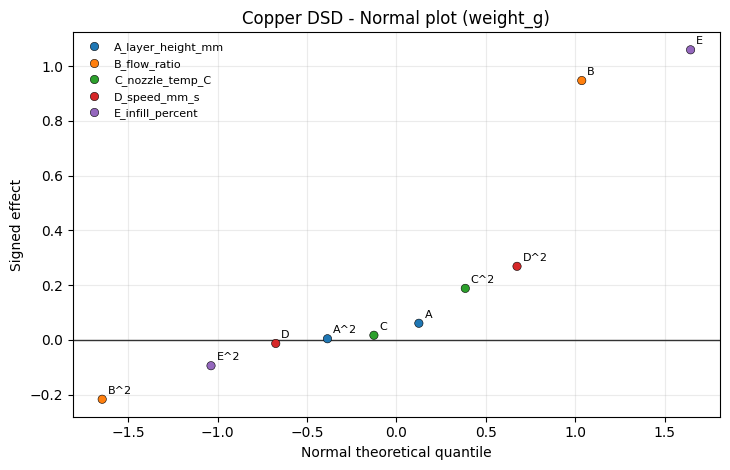

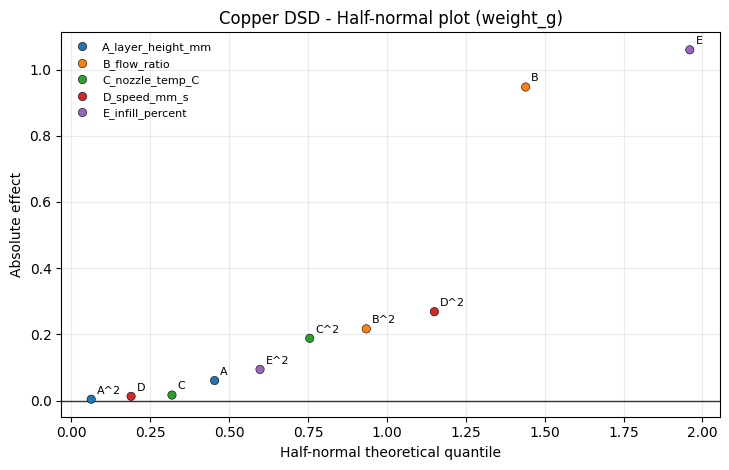

In [10]:
if copper_response_model is not None:
    plot_copper_normal_effects(copper_response_model, half_normal=False)
    plot_copper_normal_effects(copper_response_model, half_normal=True)
else:
    print("Fit a model first to show normal and half-normal effect plots.")

### 3. Main Effects Plots

These plots show the mean response at low, center, and high levels for each factor. A steep line suggests a strong main effect. A curved line suggests possible quadratic behavior.

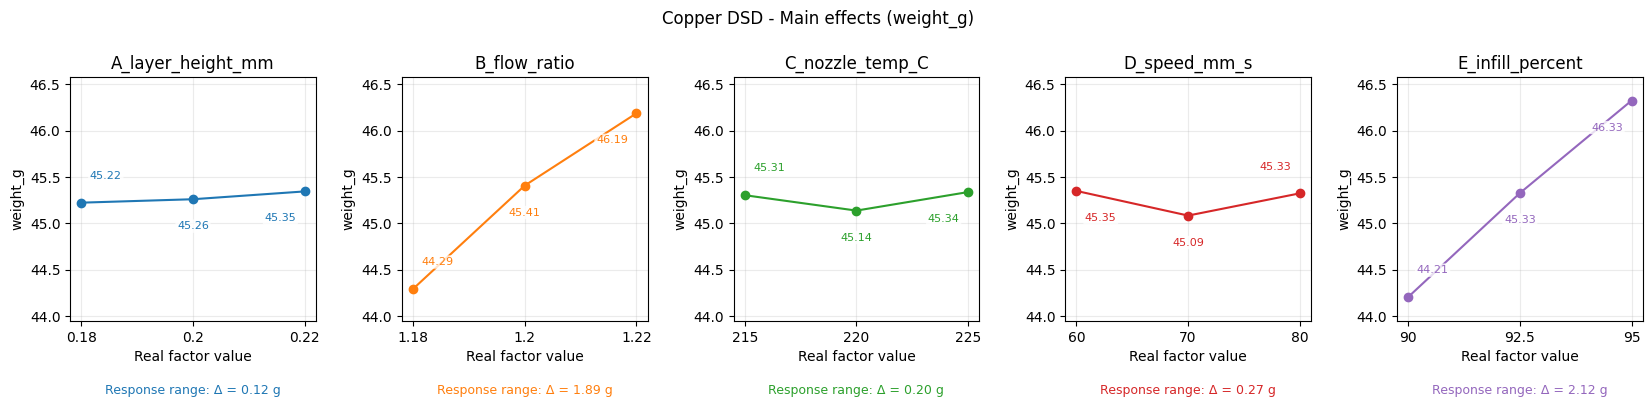

In [11]:
plot_copper_main_effects(
    copper_coded_response_table,
    copper_factor_levels,
    response=COPPER_RESPONSE,
    factor_names=copper_factor_names,
)

### Cross-Material Main-Effect Correlation: PLA FD_I vs Copper DSD

This comparison uses the signed low-to-high coded effects on the gram-scale mass/weight response. Four factors describe the same physical direction in both experiments: flow ratio, nozzle temperature, speed, and layer height. PLA-only line width and wall count, and copper-only infill, are excluded.

Each material's effects are divided by its largest absolute effect before plotting. This makes the patterns visually comparable without changing Pearson or Spearman correlation. With only four matched factors, treat the coefficients as exploratory; a high Pearson value can be driven by one dominant factor, so the Spearman value is shown as a rank-based check.

In [ ]:
from pla_doe_measurements import FD_I_RUNS
from ffd_utils import fit_main_effect_screening_model

PLA_FD_I_FACTOR_COLUMNS = [
    "A_flow_ratio",
    "B_nozzle_temp",
    "C_speed",
    "D_line_width",
    "E_layer_height",
    "F_walls",
]

shared_factor_map = [
    ("Flow ratio", "A_flow_ratio", "B_flow_ratio"),
    ("Nozzle temperature", "B_nozzle_temp", "C_nozzle_temp_C"),
    ("Speed", "C_speed", "D_speed_mm_s"),
    ("Layer height", "E_layer_height", "A_layer_height_mm"),
]

# Build PLA FD_I directly from its source data, so this notebook does not
# depend on cells having been run in the PLA notebook.
pla_fd_I_mass_matrix = pd.DataFrame([
    {
        "Run": run["run"],
        **run["coded_parameters"],
        "mass_mean_g": np.mean(run["mass_g"]) if run["mass_g"] else np.nan,
    }
    for run in FD_I_RUNS
])
pla_fd_I_main_effect_model = fit_main_effect_screening_model(
    pla_fd_I_mass_matrix,
    response="mass_mean_g",
    factor_cols=PLA_FD_I_FACTOR_COLUMNS,
)

# Fit a main-effects-only copper model for a like-for-like comparison.
copper_main_effect_correlation_model = fit_copper_response_model(
    copper_coded_response_table,
    response=COPPER_RESPONSE,
    terms=default_dsd_terms(copper_factor_names),
)

pla_coefficients = pla_fd_I_main_effect_model["coefficients"]
copper_coefficients = copper_main_effect_correlation_model["coefficients"]
main_effect_correlation_df = pd.DataFrame([
    {
        "factor": label,
        "PLA FD_I effect (g)": 2 * pla_coefficients[pla_factor],
        "Copper DSD effect (g)": 2 * copper_coefficients[copper_factor],
    }
    for label, pla_factor, copper_factor in shared_factor_map
])

for effect_col, relative_col in [
    ("PLA FD_I effect (g)", "PLA relative effect"),
    ("Copper DSD effect (g)", "Copper relative effect"),
]:
    effect_scale = main_effect_correlation_df[effect_col].abs().max()
    main_effect_correlation_df[relative_col] = (
        main_effect_correlation_df[effect_col] / effect_scale
        if pd.notna(effect_scale) and effect_scale > 0
        else np.nan
    )

pearson_r = main_effect_correlation_df["PLA relative effect"].corr(
    main_effect_correlation_df["Copper relative effect"]
)
spearman_r = main_effect_correlation_df["PLA relative effect"].corr(
    main_effect_correlation_df["Copper relative effect"],
    method="spearman",
)

display(main_effect_correlation_df.round(4))

fig, ax = plt.subplots(figsize=(7.2, 6.2))
point_colors = ["#e66101", "#5e3c99", "#1b9e77", "#d95f02"]
x = main_effect_correlation_df["PLA relative effect"].to_numpy()
y = main_effect_correlation_df["Copper relative effect"].to_numpy()
ax.scatter(x, y, s=95, c=point_colors, edgecolor="black", linewidth=0.7, zorder=3)

for _, row in main_effect_correlation_df.iterrows():
    ax.annotate(
        row["factor"],
        (row["PLA relative effect"], row["Copper relative effect"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9,
    )

if np.isfinite(pearson_r):
    slope, intercept = np.polyfit(x, y, 1)
    fit_x = np.linspace(-1.08, 1.08, 100)
    ax.plot(fit_x, slope * fit_x + intercept, color="#444444", linewidth=1.4, label="Linear fit")

ax.axhline(0, color="#999999", linewidth=0.9)
ax.axvline(0, color="#999999", linewidth=0.9)
ax.plot([-1.08, 1.08], [-1.08, 1.08], linestyle="--", color="#bbbbbb", linewidth=1, label="Equal relative effect")
ax.set_xlim(-1.12, 1.12)
ax.set_ylim(-1.12, 1.12)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("PLA FD_I relative signed mass effect")
ax.set_ylabel("Copper DSD relative signed weight effect")
ax.set_title("Shared-factor main-effect correlation: PLA FD_I vs Copper DSD")
ax.text(
    0.03,
    0.97,
    f"Pearson r = {pearson_r:.3f}\nSpearman rho = {spearman_r:.3f}\nn = {len(main_effect_correlation_df)} factors",
    transform=ax.transAxes,
    ha="left",
    va="top",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9, "edgecolor": "#cccccc"},
)
ax.grid(alpha=0.22)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show(block=False)


### 4. Curvature Plots

The DSD uses three levels, so the full 13-run dataset can estimate individual quadratic terms such as flow ratio squared, temperature squared, speed squared, layer height squared, and infill squared.

In [ ]:
if measured_count >= len(quadratic_terms) + 1:
    copper_quadratic_model = fit_copper_response_model(
        copper_coded_response_table,
        response=COPPER_RESPONSE,
        terms=quadratic_terms,
    )
    display(copper_quadratic_model["coefficient_df"].round(4))
    copper_quadratic_anova_table = build_copper_anova_table(copper_quadratic_model)
    display(copper_quadratic_anova_table.round(4))
    display(build_copper_term_significance_table(copper_quadratic_model).round(4))
    plot_copper_anova(
        copper_quadratic_anova_table,
        response=COPPER_RESPONSE,
        title="Copper DSD - ANOVA for quadratic model",
    )
    plot_copper_curvature(copper_quadratic_model)
else:
    copper_quadratic_model = None
    print("Curvature plot waits for enough measured runs to fit main effects plus five quadratic terms.")

### 5. Selected Interaction Plots

Only physically plausible interactions are prepared here. Crossing or strongly nonparallel lines suggest an interaction. Do not fit every possible interaction simultaneously with only 13 runs.

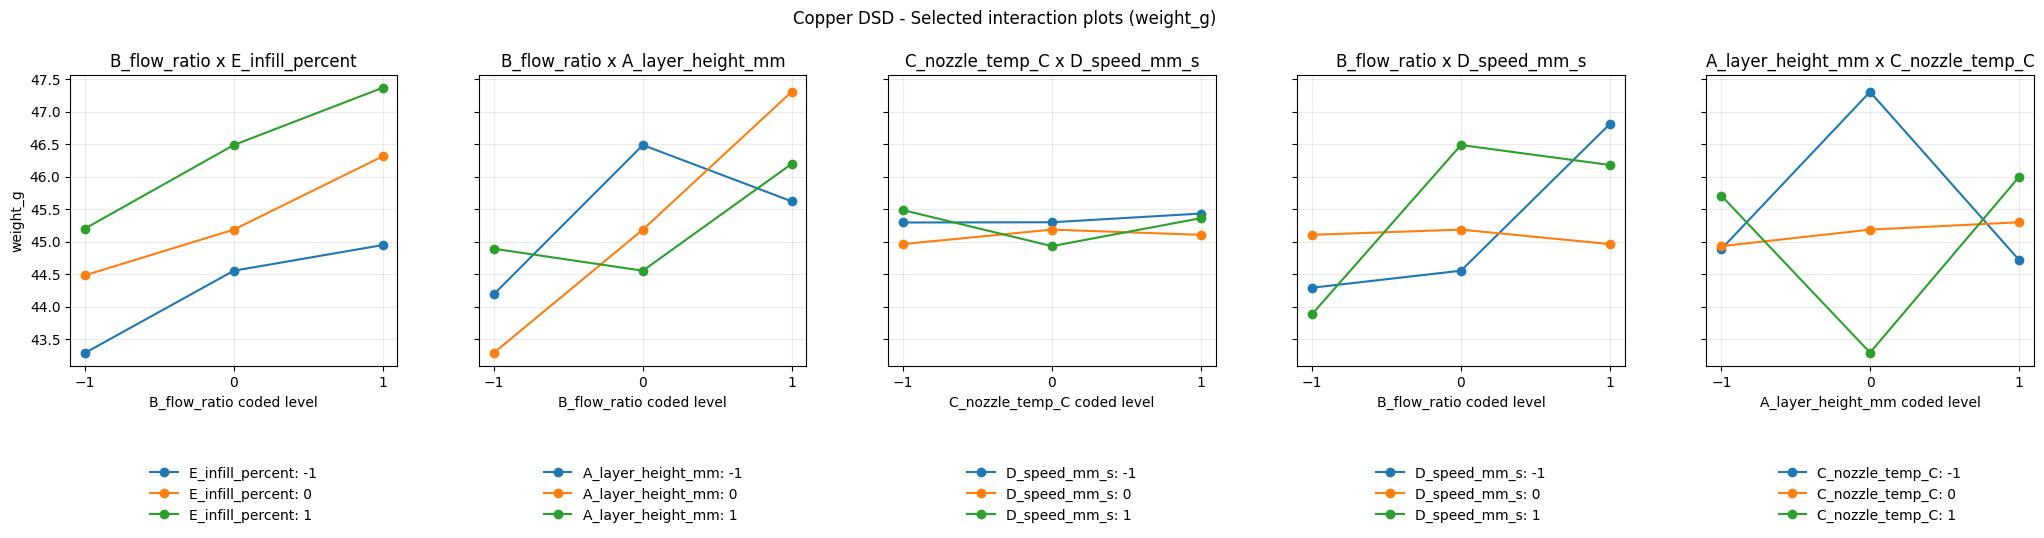

In [13]:
plot_copper_interactions(
    copper_coded_response_table,
    response=COPPER_RESPONSE,
    interaction_pairs=COPPER_SELECTED_INTERACTIONS,
);

### 6. Actual Versus Predicted Plot

This compares measured response values with model predictions. Points close to the diagonal indicate good agreement. Large deviations can indicate outliers, missing terms, or experimental variation.

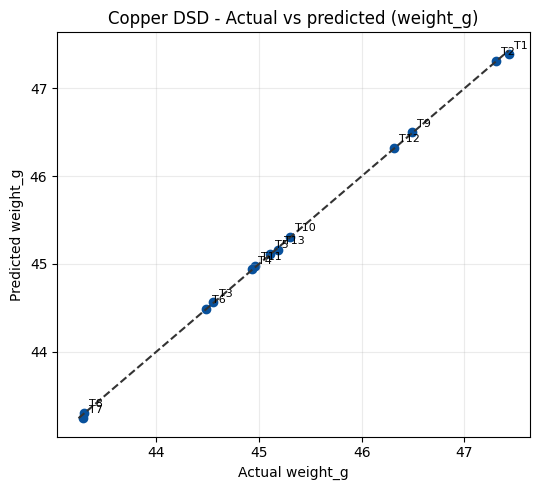

In [14]:
if copper_response_model is not None:
    plot_copper_actual_vs_predicted(copper_response_model)
else:
    print("Fit a model first to show actual versus predicted values.")

### 7. Residual Plots

Residual diagnostics include residuals versus predicted values, a normal probability plot, residuals versus print order, and residuals versus each factor. Residuals versus print order are especially important because nozzle condition, filament condition, room conditions, and machine heating can drift during Filamet experiments.

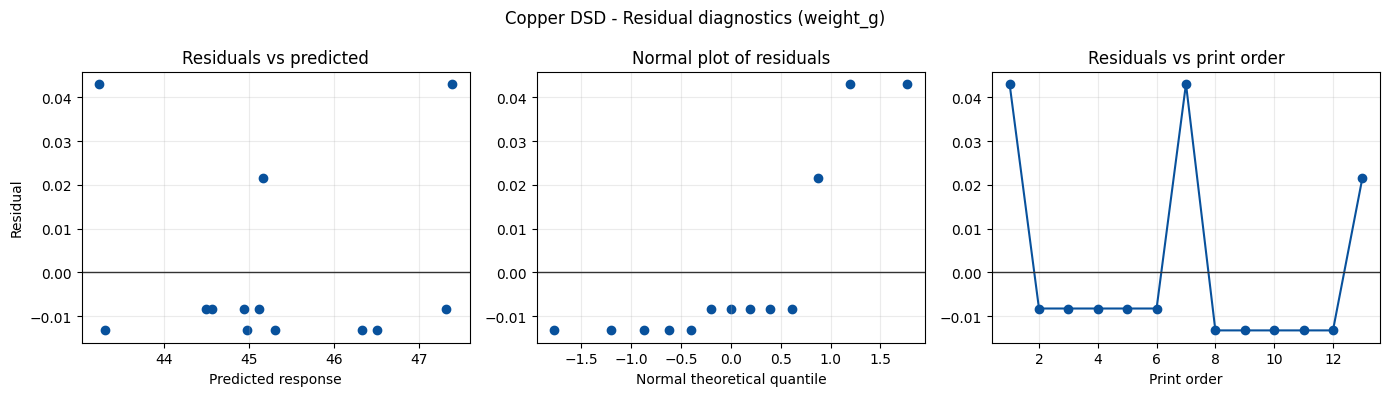

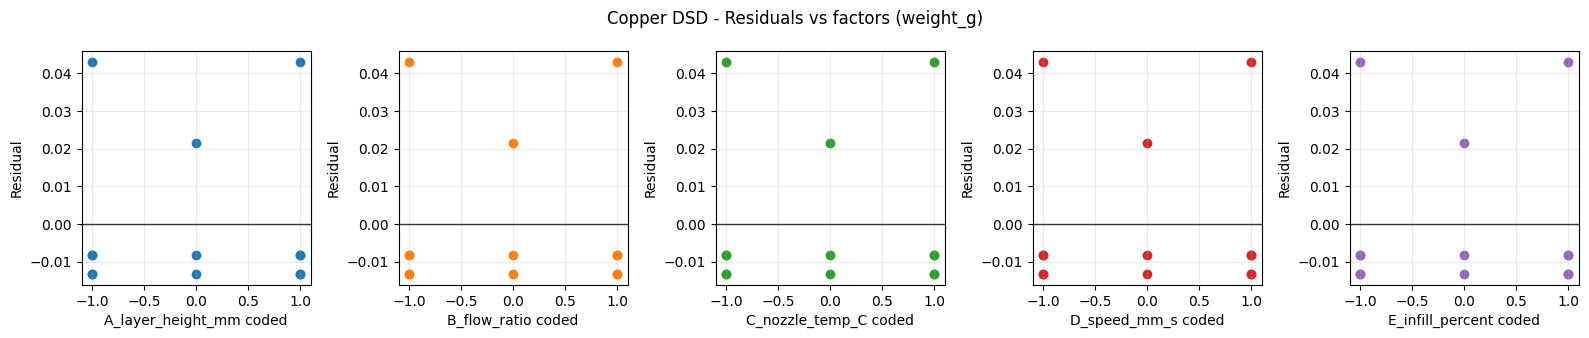

In [15]:
if copper_response_model is not None:
    plot_copper_residuals(copper_response_model, copper_factor_names)
else:
    print("Fit a model first to show residual diagnostics.")

### 8. Contour Plots

These contour plots are two-factor slices through the fitted original `T1`-`T13` model. All factors not shown on the axes are held at their center level.

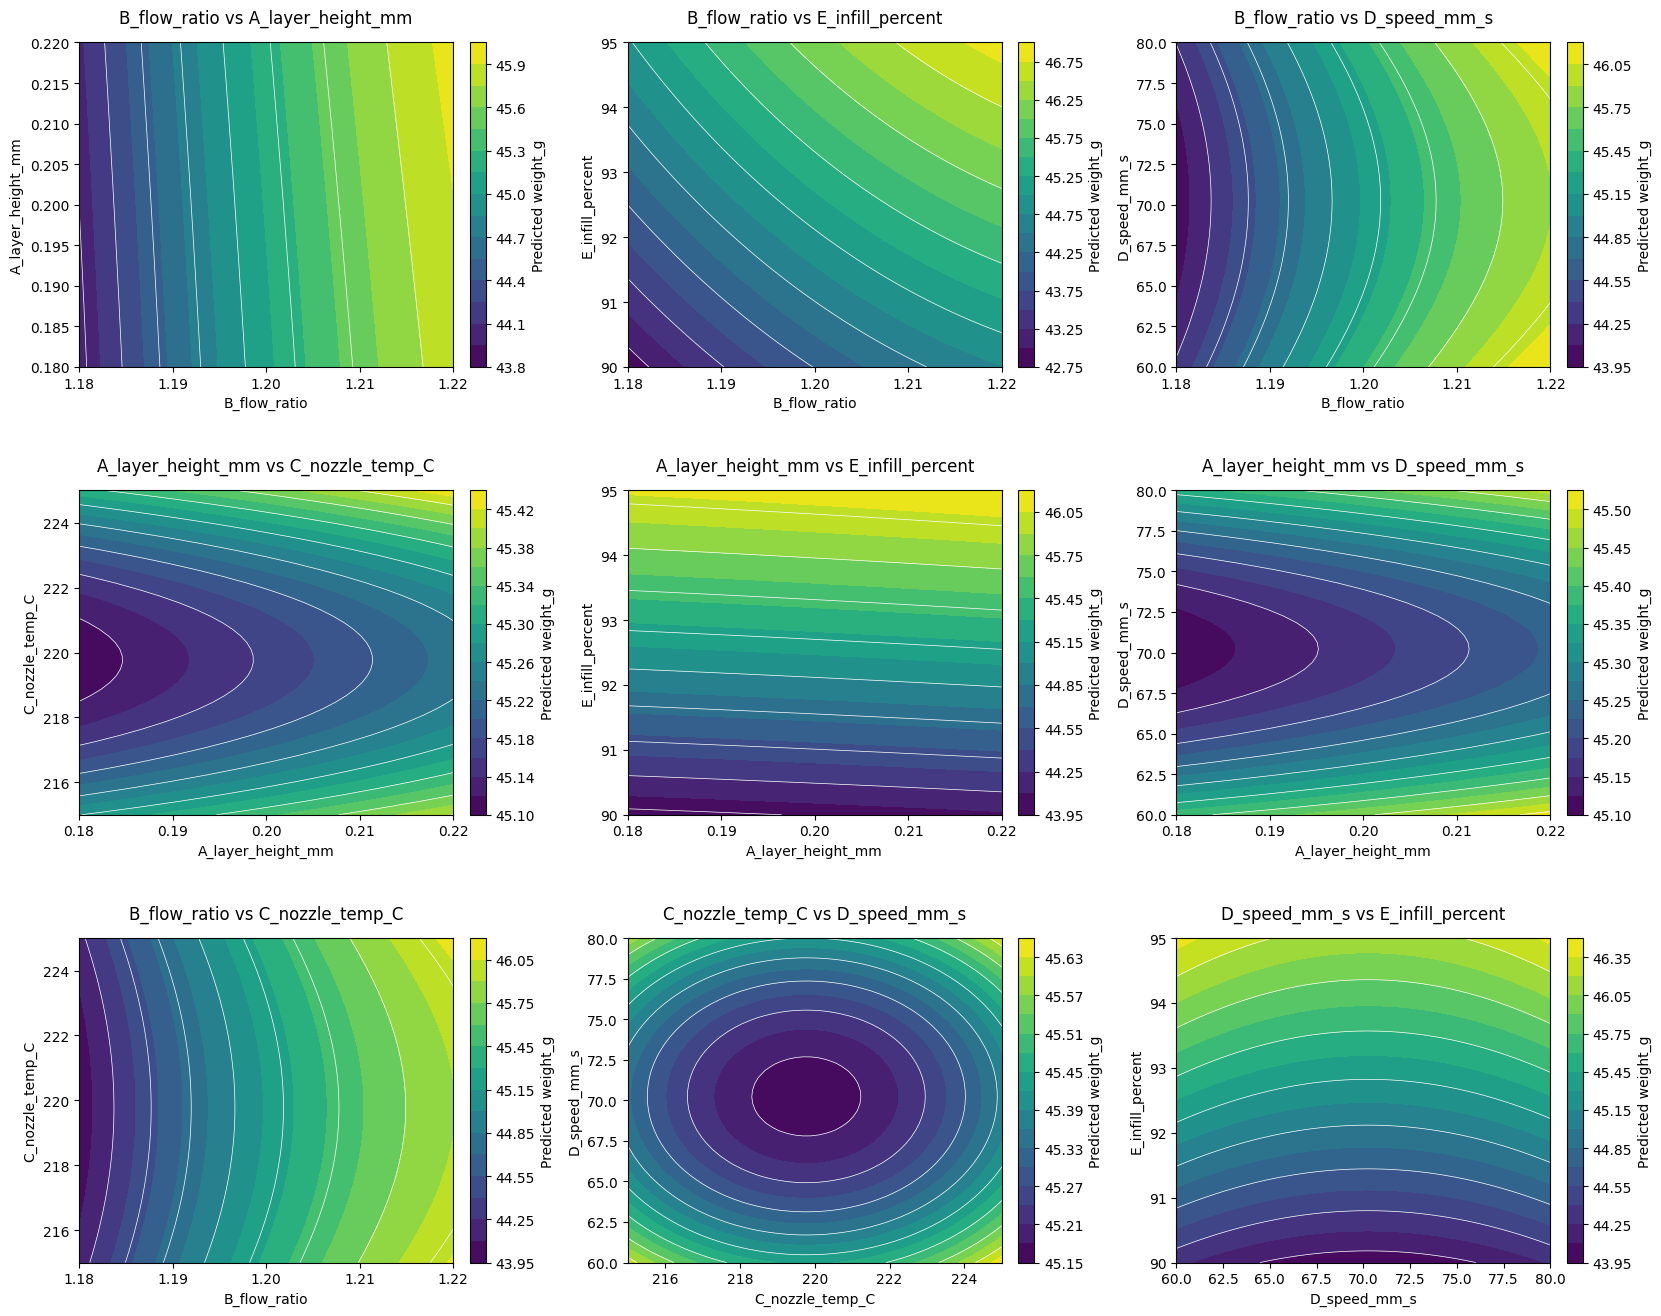

In [16]:
final_contour_model = copper_quadratic_model or copper_response_model
if final_contour_model is not None:
    plot_copper_contours(
        final_contour_model,
        levels=copper_factor_levels,
        factor_pairs=COPPER_CONTOUR_PAIRS,
        fixed_level=0,
    )
else:
    print("Fit a reduced model first to show contour plots.")

## Augmented Copper Regression Analysis: T1-T17 with T13 Repeats

This second model adds `T14`-`T17` and includes `T13.1` and `T13.2` as separate center-repeat observations alongside `T13`. Because the design is now augmented and no longer purely orthogonal, these plots should be read as ordinary coded regression results for the expanded data set.

In [ ]:
if augmented_measured_count >= len(copper_augmented_model_terms) + 1:
    copper_augmented_response_model = fit_copper_response_model(
        copper_augmented_response_table,
        response=COPPER_RESPONSE,
        terms=copper_augmented_model_terms,
    )
    display(copper_augmented_response_model["coefficient_df"].round(4))
    copper_augmented_anova_table = build_copper_anova_table(copper_augmented_response_model)
    display(copper_augmented_anova_table.round(4))
    display(build_copper_term_significance_table(copper_augmented_response_model).round(4))
    plot_copper_anova(
        copper_augmented_anova_table,
        response=COPPER_RESPONSE,
        title="Copper augmented DSD - ANOVA",
    )

    plot_copper_pareto(copper_augmented_response_model)
    plot_copper_normal_effects(copper_augmented_response_model, half_normal=False)
    plot_copper_normal_effects(copper_augmented_response_model, half_normal=True)

    plot_copper_main_effects(
        copper_augmented_response_table,
        copper_factor_levels,
        response=COPPER_RESPONSE,
        factor_names=copper_factor_names,
    )

    if copper_augmented_model_terms == quadratic_terms:
        plot_copper_curvature(copper_augmented_response_model)

    plot_copper_interactions(
        copper_augmented_response_table,
        response=COPPER_RESPONSE,
        interaction_pairs=COPPER_SELECTED_INTERACTIONS,
    )
    plot_copper_actual_vs_predicted(copper_augmented_response_model)
    plot_copper_residuals(copper_augmented_response_model, copper_factor_names)
    plot_copper_contours(
        copper_augmented_response_model,
        levels=copper_factor_levels,
        factor_pairs=COPPER_CONTOUR_PAIRS,
        fixed_level=0,
    )
else:
    copper_augmented_response_model = None
    print("Not enough measured runs yet for the augmented model with T13 repeats.")


### 9. Multiresponse Desirability

This combines available responses into one compromise score. Density is maximised. Porosity, leakage, and visible clumping are minimised. The desirability table updates automatically once those columns are filled in the measurement JSON.

In [18]:
copper_desirability_table = build_copper_desirability_table(copper_measurement_table)
display(copper_desirability_table[[
    "Run",
    "density_g_cm3",
    "porosity_percent",
    "log_leakage_rate",
    "visible_clumping_score",
    "overall_desirability",
]])
plot_copper_desirability(copper_desirability_table)

,Run,density_g_cm3,porosity_percent,log_leakage_rate,visible_clumping_score,overall_desirability
0,T1,None,None,None,None,NaN
1,T2,None,None,None,None,NaN
2,T3,None,None,None,None,NaN
3,T4,None,None,None,None,NaN
4,T5,None,None,None,None,NaN
5,T6,None,None,None,None,NaN
6,T7,None,None,None,None,NaN
7,T8,None,None,None,None,NaN
8,T9,None,None,None,None,NaN
9,T10,None,None,None,None,NaN


No desirability plot yet: add density, porosity, leakage, or clumping responses.
